# California Housing Price Prediction

**Problem statement:** Predict the median house value for each district using district-level features.

**Target column:** `median_house_value`

**Problem type:** Regression


> **After original cell 001:** Good start. The problem is now framed as a regression task with a clear target variable.


> **Before original cell 002:** This heading begins the setup section of the notebook.


## 1. Import Libraries


> **After original cell 002:** Good section marker. I corrected the spelling and made the heading clearer.


> **Before original cell 003:** Load the general-purpose libraries needed for download, data handling, and plotting.


In [1]:
import os
import tarfile
import urllib.request
import ssl
import shutil
import certifi
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

> **After original cell 003:** The imports are appropriate for the notebook. `pandas` is imported later; grouping it here would also be fine.


> **Before original cell 004:** Define the dataset URL, local storage path, and reusable download function.


In [2]:
# Function to fetch the data
DOWNLOAD_ROOT = "https://raw.githubusercontent.com/ageron/handson-ml2/master/"
HOUSING_PATH = os.path.join("datasets", "housing")
HOUSING_URL = DOWNLOAD_ROOT + "datasets/housing/housing.tgz"

def fetch_housing_data(housing_url=HOUSING_URL, housing_path=HOUSING_PATH):
    os.makedirs(housing_path, exist_ok=True)

    tgz_path = os.path.join(housing_path, "housing.tgz")

    context = ssl.create_default_context(cafile=certifi.where())

    with urllib.request.urlopen(housing_url, context=context) as response:
        with open(tgz_path, "wb") as file:
            shutil.copyfileobj(response, file)

    with tarfile.open(tgz_path) as housing_tgz:
        housing_tgz.extractall(path=housing_path)

> **After original cell 004:** The function correctly downloads and extracts the dataset. The SSL/certifi handling is useful for your Mac setup.


> **Before original cell 005:** Run the download function before trying to load the CSV file.


In [3]:
fetch_housing_data()

> **After original cell 005:** This makes the notebook reproducible when the dataset folder is missing. It needs internet access on the first run.


> **Before original cell 006:** Create a small loader function that reads the housing CSV into pandas.


In [4]:
# Load the data using pandas
import pandas as pd
def load_housing_data(housing_path=HOUSING_PATH):
    csv_path = os.path.join(housing_path, "housing.csv")
    return pd.read_csv(csv_path)

> **After original cell 006:** Good reusable loader. Keeping the path logic in one place makes later changes easier.


> **Before original cell 007:** Load the raw dataset into the `housing` DataFrame.


In [5]:
housing = load_housing_data()

> **After original cell 007:** The raw dataset is now available for EDA and splitting.


> **Before original cell 008:** Look at the first few records to confirm the column names and basic values.


In [6]:
housing.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


> **After original cell 008:** Good sanity check. The dataset structure is visible before deeper analysis.


> **Before original cell 009:** View a random sample so you do not only inspect the first rows.


In [7]:
housing.sample(10, random_state=42)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
20046,-119.01,36.06,25.0,1505.0,NaN,1392.0,359.0,1.6812,47700.0,INLAND
3024,-119.46,35.14,30.0,2943.0,NaN,1565.0,584.0,2.5313,45800.0,INLAND
15663,-122.44,37.80,52.0,3830.0,NaN,1310.0,963.0,3.4801,500001.0,NEAR BAY
20484,-118.72,34.28,17.0,3051.0,NaN,1705.0,495.0,5.7376,218600.0,<1H OCEAN
9814,-121.93,36.62,34.0,2351.0,NaN,1063.0,428.0,3.7250,278000.0,NEAR OCEAN
13311,-117.61,34.08,12.0,4427.0,NaN,2400.0,843.0,4.7147,158700.0,INLAND
7113,-118.02,33.89,36.0,1375.0,NaN,670.0,221.0,5.0839,198200.0,<1H OCEAN
7668,-118.08,33.92,38.0,1335.0,NaN,1011.0,269.0,3.6908,157500.0,<1H OCEAN
18246,-122.08,37.39,4.0,2292.0,NaN,1050.0,584.0,4.8036,340000.0,NEAR BAY
5723,-118.23,34.18,45.0,2332.0,NaN,943.0,339.0,8.1132,446600.0,<1H OCEAN


> **After original cell 009:** Good use of `random_state`; the sample is reproducible.


> **Before original cell 010:** Check the final rows of the dataset for any obvious formatting issue.


In [8]:
housing.tail()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND
20639,-121.24,39.37,16.0,2785.0,616.0,1387.0,530.0,2.3886,89400.0,INLAND


> **After original cell 010:** Useful quick check, though `head` plus `sample` is usually enough.


> **Before original cell 011:** Check the number of rows and columns before preprocessing.


In [9]:
housing.shape

(20640, 10)

> **After original cell 011:** Good baseline shape check before creating train and test sets.


> **Before original cell 012:** Create a schema-style summary for data types, missing values, uniqueness, and duplicates.


In [10]:
schema = pd.DataFrame(
    {
        "dtype":housing.dtypes,
        "non-null":housing.notna().sum(),
        "missing":housing.isna().sum(),
        "missing_pct":housing.isna().mean()*100,
        "unique":housing.nunique(dropna=False),
        "Duplicated":housing.duplicated().sum()
    }
).sort_values("missing_pct", ascending=False)
schema

,dtype,non-null,missing,missing_pct,unique,Duplicated
total_bedrooms,float64,20433,207,1.002907,1924,0
longitude,float64,20640,0,0.000000,844,0
latitude,float64,20640,0,0.000000,862,0
housing_median_age,float64,20640,0,0.000000,52,0
total_rooms,float64,20640,0,0.000000,5926,0
population,float64,20640,0,0.000000,3888,0
households,float64,20640,0,0.000000,1815,0
median_income,float64,20640,0,0.000000,12928,0
median_house_value,float64,20640,0,0.000000,3842,0
ocean_proximity,str,20640,0,0.000000,5,0


> **After original cell 012:** Strong EDA cell. Note that the duplicate count is dataset-level and is repeated for every feature row.


> **Before original cell 013:** Generate summary statistics for numeric columns.


In [11]:
housing.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


> **After original cell 013:** Good numeric overview. This helps reveal scale differences and possible target capping.


> **Before original cell 014:** Define the target column and inspect its distribution summary.


In [12]:
target = "median_house_value"
housing[target].describe()

count     20640.000000
mean     206855.816909
std      115395.615874
min       14999.000000
25%      119600.000000
50%      179700.000000
75%      264725.000000
max      500001.000000
Name: median_house_value, dtype: float64

> **After original cell 014:** Correct. Setting `target` makes later target-specific analysis easier.


> **Before original cell 015:** Inspect important target percentiles to understand the price range.


In [13]:
housing[target].quantile([0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])

0.01     50000.0
0.05     66200.0
0.25    119600.0
0.50    179700.0
0.75    264725.0
0.95    489810.0
0.99    500001.0
Name: median_house_value, dtype: float64

> **After original cell 015:** Good. Percentiles are useful for spotting extreme values and the upper-price cap.


> **Before original cell 016:** Plot the target distribution to see skewness and concentration of house values.


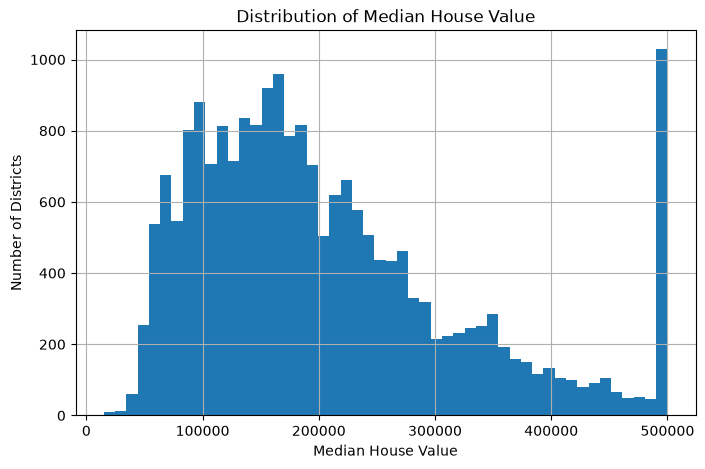

In [14]:
housing[target].hist(bins = 50, figsize=(8,5))
plt.xlabel("Median House Value")
plt.ylabel("Number of Districts")
plt.title("Distribution of Median House Value")
plt.show()

> **After original cell 016:** Good visualization. The upper-end clustering supports the later capped-value discussion.


> **Before original cell 017:** Plot histograms for all numeric features to understand scale and skew.


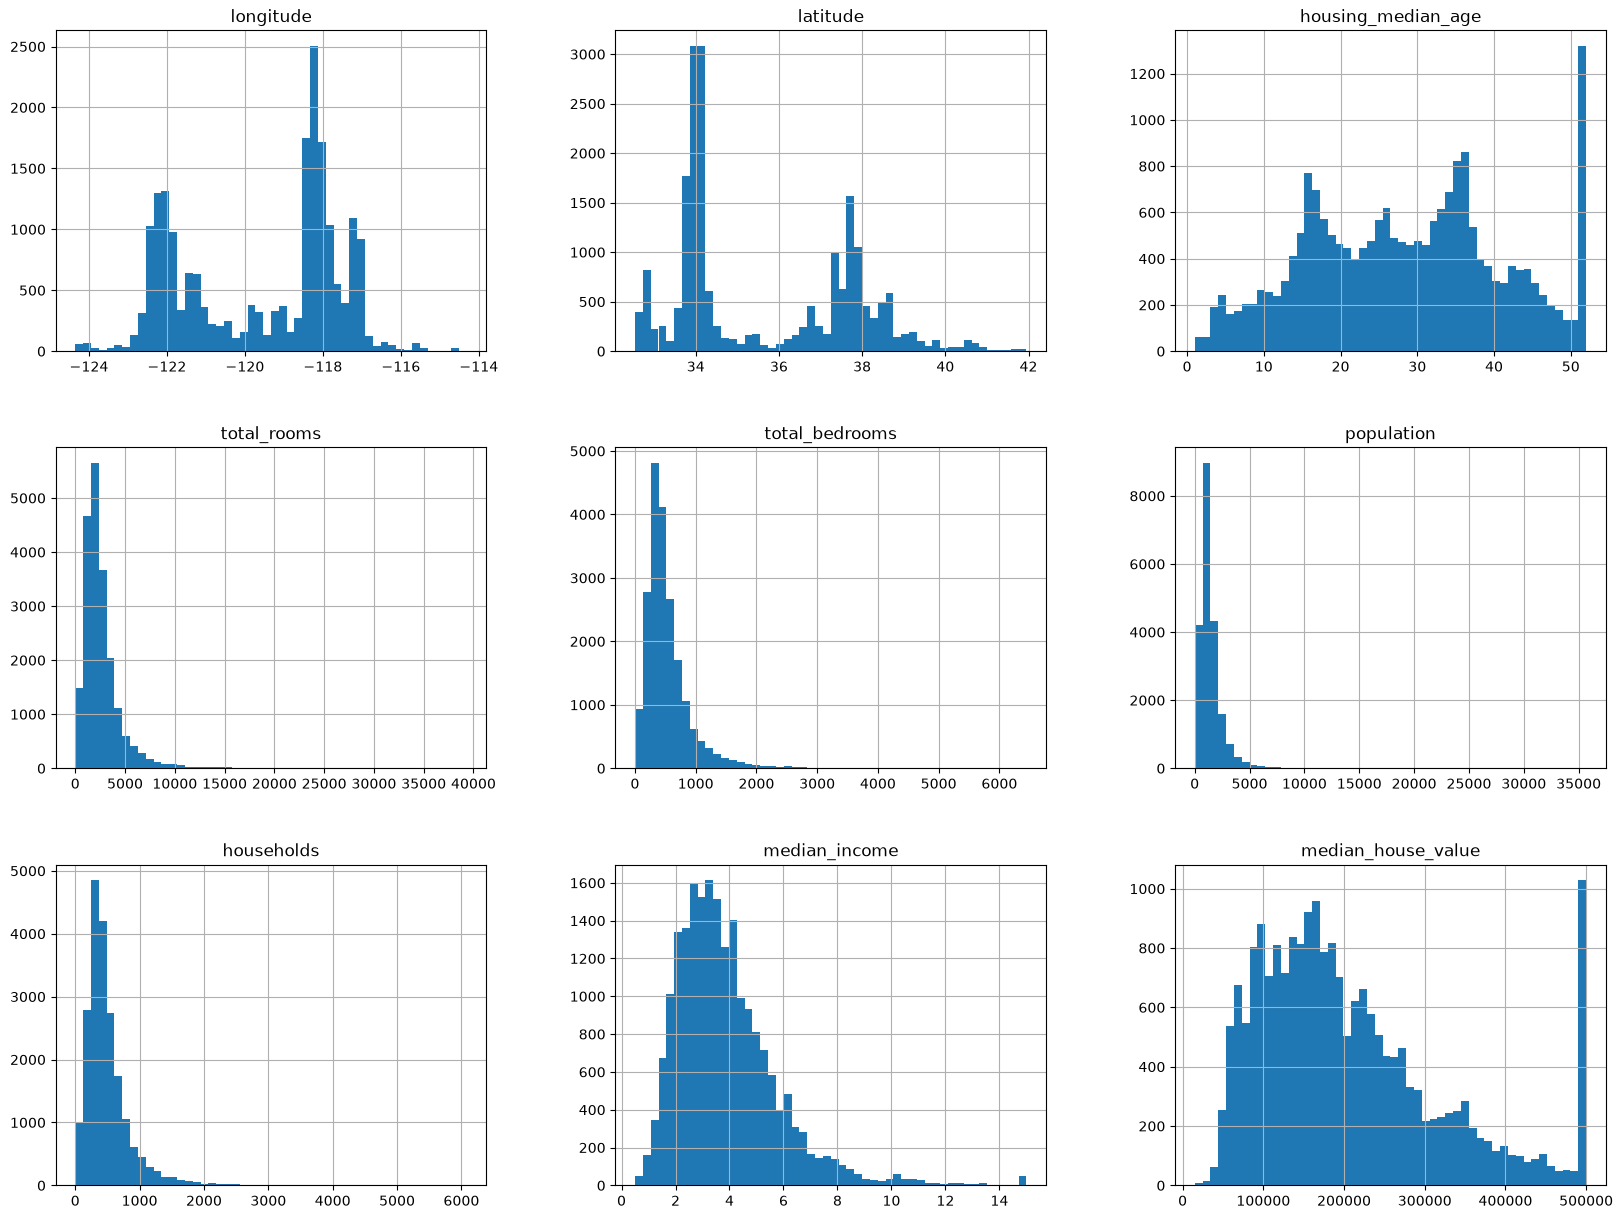

In [15]:
%matplotlib inline 
import matplotlib.pyplot as plt
housing.hist(bins=50, figsize=(20,15))
plt.show()

> **After original cell 017:** Useful EDA. `%matplotlib inline` is optional in modern Jupyter, but harmless.


> **Before original cell 018:** Create income categories so the train/test split preserves income distribution.


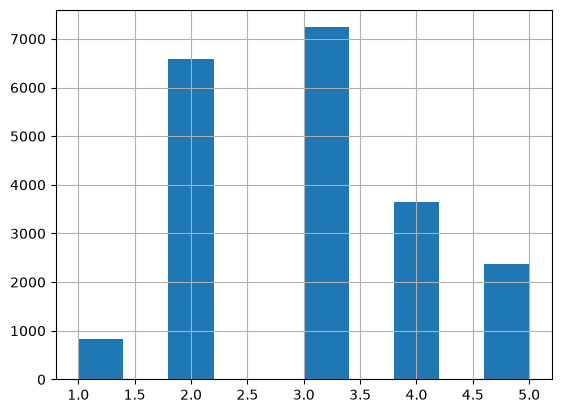

In [16]:
# Define categories for median income to support stratified sampling
housing['income_cat'] = pd.cut(housing['median_income'], bins=[0.,1.5,3.0,4.5,6.0,np.inf], labels=[1,2,3,4,5]) 
housing['income_cat'].hist()
plt.show()

> **After original cell 018:** Good Hands-On ML technique. Stratifying by income is sensible because income is strongly related to house value.


> **Before original cell 019:** Initialize a reproducible stratified train/test split.


In [17]:
# Perform train and test split using Stratified Shuffle Split
from sklearn.model_selection import StratifiedShuffleSplit
split = StratifiedShuffleSplit(n_splits=1,  test_size=0.2, random_state=42)
split.get_n_splits()

1

> **After original cell 019:** Correct setup: 20% test data and fixed `random_state` for repeatability.


> **Before original cell 020:** Apply the stratified split to create training and test DataFrames.


In [18]:
for train_index, test_index in split.split(housing, housing['income_cat']):
    train_set = housing.loc[train_index]
    test_set = housing.loc[test_index]

> **After original cell 020:** Good. The test set is created once and stays untouched until final evaluation.


> **Before original cell 021:** Remove the temporary stratification column and separate features from the target.


In [19]:
for dataset in (train_set, test_set):
    dataset.drop(columns="income_cat", inplace=True)

# Separate input features and target
X_train = train_set.drop(columns="median_house_value")
y_train = train_set["median_house_value"].copy()

X_test = test_set.drop(columns="median_house_value")
y_test = test_set["median_house_value"].copy()

> **After original cell 021:** Correct. `X_train`, `y_train`, `X_test`, and `y_test` are now ready.


> **Before original cell 022:** Validate the split shapes, feature list, and missing values.


In [20]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test :", X_test.shape)
print("y_test :", y_test.shape)

print("\nTraining features:")
print(X_train.columns.tolist())

print("\nMissing values:")
print(X_train.isna().sum())

X_train: (16512, 9)
y_train: (16512,)
X_test : (4128, 9)
y_test : (4128,)

Training features:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'ocean_proximity']

Missing values:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        158
population              0
households              0
median_income           0
ocean_proximity         0
dtype: int64


> **After original cell 022:** Good checkpoint. It confirms the missing `total_bedrooms` values that the pipeline must impute.


> **Before original cell 023:** Define a custom scikit-learn transformer for domain-inspired ratio features.


In [21]:
# Feature-engineering transformer
import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, TransformerMixin


class HousingFeatureEngineer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        if not isinstance(X, pd.DataFrame):
            raise TypeError("HousingFeatureEngineer expects a pandas DataFrame.")

        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        self.n_features_in_ = len(self.feature_names_in_)

        return self

    def transform(self, X):
        X = X.copy()

        # Replace zero denominators with NaN.
        # The numerical imputer will handle these values later.
        households = X["households"].replace(0, np.nan)
        total_rooms = X["total_rooms"].replace(0, np.nan)

        X["rooms_per_household"] = (
            X["total_rooms"] / households
        )

        X["bedrooms_per_room"] = (
            X["total_bedrooms"] / total_rooms
        )

        X["population_per_household"] = (
            X["population"] / households
        )

        return X

    def get_feature_names_out(self, input_features=None):
        if input_features is None:
            input_features = self.feature_names_in_

        return np.asarray([
            *input_features,
            "rooms_per_household",
            "bedrooms_per_room",
            "population_per_household",
        ], dtype=object)

> **After original cell 023:** Strong cell. It follows the estimator API and handles zero denominators by creating NaN values for later imputation.


> **Before original cell 024:** Preview the engineered features on a small subset before using the transformer in the full pipeline.


In [22]:
feature_engineer = HousingFeatureEngineer()

engineered_preview = feature_engineer.fit_transform(
    X_train.head()
)

engineered_preview[[
    "total_rooms",
    "total_bedrooms",
    "population",
    "households",
    "rooms_per_household",
    "bedrooms_per_room",
    "population_per_household",
]]

,total_rooms,total_bedrooms,population,households,rooms_per_household,bedrooms_per_room,population_per_household
12655,3873.0,797.0,2237.0,706.0,5.485836,0.205784,3.168555
15502,5320.0,855.0,2015.0,768.0,6.927083,0.160714,2.623698
2908,1618.0,310.0,667.0,300.0,5.393333,0.191595,2.223333
14053,1877.0,519.0,898.0,483.0,3.886128,0.276505,1.859213
20496,3536.0,646.0,1837.0,580.0,6.096552,0.182692,3.167241


> **After original cell 024:** Good verification. The ratio features are easy to inspect here.


> **Before original cell 025:** Build preprocessing for numeric and categorical features inside a single pipeline.


In [23]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder


numerical_features = [
    "longitude",
    "latitude",
    "housing_median_age",
    "total_rooms",
    "total_bedrooms",
    "population",
    "households",
    "median_income",
    "rooms_per_household",
    "bedrooms_per_room",
    "population_per_household",
]

categorical_features = [
    "ocean_proximity",
]


numerical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
])


categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "encoder",
        OneHotEncoder(handle_unknown="ignore")
    ),
])


preprocessor = ColumnTransformer([
    (
        "numerical",
        numerical_pipeline,
        numerical_features
    ),
    (
        "categorical",
        categorical_pipeline,
        categorical_features
    ),
])


preprocessing_pipeline = Pipeline([
    (
        "feature_engineering",
        HousingFeatureEngineer()
    ),
    (
        "preprocessor",
        preprocessor
    ),
])

> **After original cell 025:** Good design. Imputation and one-hot encoding stay inside cross-validation, which prevents leakage.


> **Before original cell 026:** Fit the preprocessing pipeline on training data and inspect the transformed matrix.


In [24]:
from scipy import sparse


X_train_prepared = preprocessing_pipeline.fit_transform(
    X_train
)

print("Raw training shape     :", X_train.shape)
print("Prepared training shape:", X_train_prepared.shape)

feature_names = (
    preprocessing_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

print("\nFinal model features:")
for feature in feature_names:
    print(feature)

if sparse.issparse(X_train_prepared):
    prepared_values = X_train_prepared.data
else:
    prepared_values = X_train_prepared

print(
    "\nContains missing values:",
    np.isnan(prepared_values).any()
)

Raw training shape     : (16512, 9)
Prepared training shape: (16512, 16)

Final model features:
numerical__longitude
numerical__latitude
numerical__housing_median_age
numerical__total_rooms
numerical__total_bedrooms
numerical__population
numerical__households
numerical__median_income
numerical__rooms_per_household
numerical__bedrooms_per_room
numerical__population_per_household
categorical__ocean_proximity_<1H OCEAN
categorical__ocean_proximity_INLAND
categorical__ocean_proximity_ISLAND
categorical__ocean_proximity_NEAR BAY
categorical__ocean_proximity_NEAR OCEAN

Contains missing values: False


> **After original cell 026:** Good validation. The prepared feature shape and missing-value check confirm the pipeline is working.


> **Before original cell 027:** Combine preprocessing and Random Forest into one baseline estimator.


In [25]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline


rf_baseline = Pipeline([
    (
        "preprocessing",
        preprocessing_pipeline
    ),
    (
        "model",
        RandomForestRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=1
        )
    ),
])

rf_baseline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_engineering', ...), ('preprocessor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its paramet

> **After original cell 027:** Correct end-to-end estimator. Because it is a pipeline, CV refits preprocessing within each fold.


> **Before original cell 028:** Fit the baseline model on the full training set and inspect training metrics.


In [26]:
from sklearn.metrics import (
    mean_absolute_error,
    r2_score,
    root_mean_squared_error,
)


rf_baseline.fit(X_train, y_train)

training_predictions = rf_baseline.predict(X_train)

training_rmse = root_mean_squared_error(
    y_train,
    training_predictions
)

training_mae = mean_absolute_error(
    y_train,
    training_predictions
)

training_r2 = r2_score(
    y_train,
    training_predictions
)

print(f"Training RMSE: ${training_rmse:,.2f}")
print(f"Training MAE : ${training_mae:,.2f}")
print(f"Training R²  : {training_r2:.4f}")

Training RMSE: $18,646.21
Training MAE : $12,056.73
Training R²  : 0.9740


> **After original cell 028:** Training performance is strong, but this alone can be misleading. Cross-validation is needed to detect overfitting.


> **Before original cell 029:** Run 5-fold cross-validation with RMSE, MAE, and R2.


In [27]:
import pandas as pd

from sklearn.model_selection import KFold, cross_validate


cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
    "r2": "r2",
}

cv_results = cross_validate(
    estimator=rf_baseline,
    X=X_train,
    y=y_train,
    scoring=scoring,
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
)

> **After original cell 029:** Good validation setup. Multiple metrics give a fuller view than RMSE alone.


> **Before original cell 030:** Convert raw cross-validation results into a readable fold-level table.


In [28]:
cv_summary = pd.DataFrame({
    "fold": range(1, cv.get_n_splits() + 1),

    "train_rmse": -cv_results["train_rmse"],
    "validation_rmse": -cv_results["test_rmse"],

    "train_mae": -cv_results["train_mae"],
    "validation_mae": -cv_results["test_mae"],

    "train_r2": cv_results["train_r2"],
    "validation_r2": cv_results["test_r2"],
})

cv_summary.round(2)

,fold,train_rmse,validation_rmse,train_mae,validation_mae,train_r2,validation_r2
0,1,18995.63,49788.87,12348.22,32689.34,0.97,0.81
1,2,18965.05,50932.72,12292.69,32831.73,0.97,0.80
2,3,19008.04,50716.07,12303.01,32758.41,0.97,0.81
3,4,18808.10,52132.29,12246.36,33672.34,0.97,0.80
4,5,19118.64,49593.60,12364.67,33045.36,0.97,0.82


> **After original cell 030:** Good. Fold-level results help you see stability instead of relying only on one average.


> **Before original cell 031:** Summarize average baseline performance and the train-validation gap.


In [29]:
mean_train_rmse = cv_summary["train_rmse"].mean()
mean_validation_rmse = cv_summary["validation_rmse"].mean()

mean_train_mae = cv_summary["train_mae"].mean()
mean_validation_mae = cv_summary["validation_mae"].mean()

mean_train_r2 = cv_summary["train_r2"].mean()
mean_validation_r2 = cv_summary["validation_r2"].mean()

rmse_gap = mean_validation_rmse - mean_train_rmse

rmse_gap_percentage = (
    rmse_gap / mean_train_rmse
) * 100

print("Random Forest Baseline")
print("-" * 40)

print(
    f"Mean training RMSE   : "
    f"${mean_train_rmse:,.2f}"
)

print(
    f"Mean validation RMSE : "
    f"${mean_validation_rmse:,.2f}"
)

print(
    f"Validation RMSE std  : "
    f"${cv_summary['validation_rmse'].std():,.2f}"
)

print(
    f"Mean training MAE    : "
    f"${mean_train_mae:,.2f}"
)

print(
    f"Mean validation MAE  : "
    f"${mean_validation_mae:,.2f}"
)

print(f"Mean training R²     : {mean_train_r2:.4f}")
print(f"Mean validation R²   : {mean_validation_r2:.4f}")

print(f"RMSE gap             : ${rmse_gap:,.2f}")
print(f"RMSE gap percentage  : {rmse_gap_percentage:.2f}%")

Random Forest Baseline
----------------------------------------
Mean training RMSE   : $18,979.09
Mean validation RMSE : $50,632.71
Validation RMSE std  : $1,017.04
Mean training MAE    : $12,310.99
Mean validation MAE  : $32,999.44
Mean training R²     : 0.9731
Mean validation R²   : 0.8084
RMSE gap             : $31,653.62
RMSE gap percentage  : 166.78%


> **After original cell 031:** Important finding: the baseline Random Forest overfits because training error is much lower than validation error.


> **Before original cell 032:** Compute a learning curve to see how performance changes with more training examples.


In [30]:
import numpy as np

from sklearn.model_selection import learning_curve


train_sizes, train_scores, validation_scores = learning_curve(
    estimator=rf_baseline,
    X=X_train,
    y=y_train,
    train_sizes=np.linspace(0.2, 1.0, 5),
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    shuffle=True,
    random_state=42,
)

# Convert negative RMSE values into positive RMSE
train_rmse_scores = -train_scores
validation_rmse_scores = -validation_scores

mean_train_rmse = train_rmse_scores.mean(axis=1)
std_train_rmse = train_rmse_scores.std(axis=1)

mean_validation_rmse = validation_rmse_scores.mean(axis=1)
std_validation_rmse = validation_rmse_scores.std(axis=1)

> **After original cell 032:** Good diagnostic. The code correctly converts scikit-learn's negative RMSE scores back to positive values.


> **Before original cell 033:** Display learning curve values in table form.


In [31]:
learning_curve_results = pd.DataFrame({
    "training_examples": train_sizes,
    "training_rmse": mean_train_rmse,
    "validation_rmse": mean_validation_rmse,
    "rmse_gap": mean_validation_rmse - mean_train_rmse,
})

learning_curve_results.round(2)

,training_examples,training_rmse,validation_rmse,rmse_gap
0,2641,20892.31,56435.28,35542.97
1,5283,20051.73,53878.90,33827.17
2,7925,19601.04,52344.04,32743.00
3,10567,19177.68,51242.00,32064.33
4,13209,18896.92,50634.66,31737.74


> **After original cell 033:** Useful. The table supports the plot and helps quantify the train-validation gap.


> **Before original cell 034:** Plot training and validation RMSE across different training sizes.


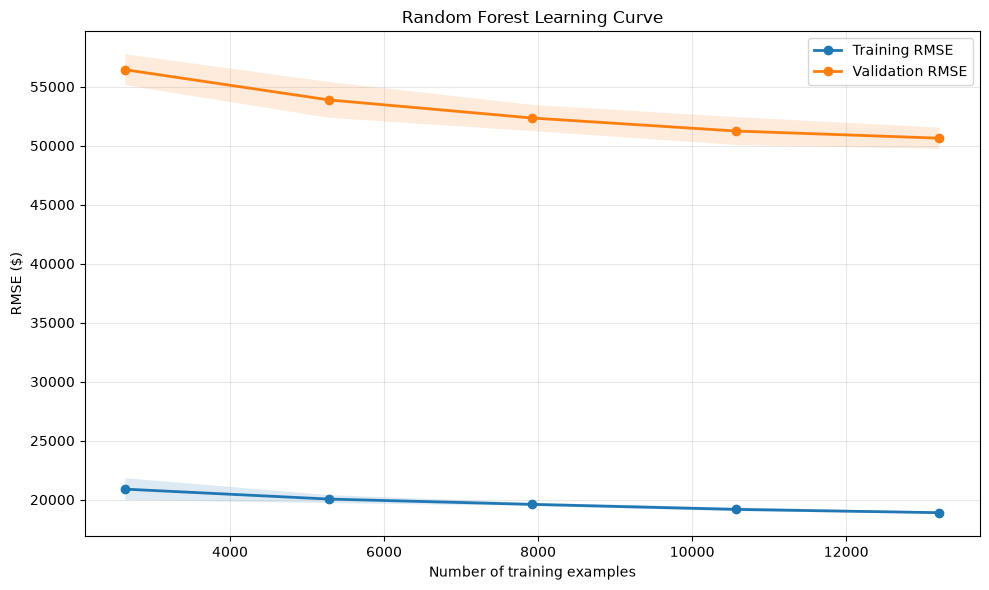

In [32]:
import matplotlib.pyplot as plt


plt.figure(figsize=(10, 6))

plt.plot(
    train_sizes,
    mean_train_rmse,
    marker="o",
    linewidth=2,
    label="Training RMSE",
)

plt.plot(
    train_sizes,
    mean_validation_rmse,
    marker="o",
    linewidth=2,
    label="Validation RMSE",
)

plt.fill_between(
    train_sizes,
    mean_train_rmse - std_train_rmse,
    mean_train_rmse + std_train_rmse,
    alpha=0.15,
)

plt.fill_between(
    train_sizes,
    mean_validation_rmse - std_validation_rmse,
    mean_validation_rmse + std_validation_rmse,
    alpha=0.15,
)

plt.xlabel("Number of training examples")
plt.ylabel("RMSE ($)")
plt.title("Random Forest Learning Curve")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

> **After original cell 034:** Good bias/variance visualization. It supports the decision to tune regularization parameters.


> **Before original cell 035:** Run a controlled experiment for `max_depth` while holding other settings stable.


In [33]:
from sklearn.base import clone
from sklearn.model_selection import cross_validate
import pandas as pd


max_depth_values = [
    5,
    10,
    15,
    20,
    25,
    30,
    None,
]

depth_results = []

for depth in max_depth_values:

    experiment_model = clone(rf_baseline)

    experiment_model.set_params(
        model__max_depth=depth,
        model__min_samples_leaf=1,
        model__min_samples_split=2,
    )

    scores = cross_validate(
        estimator=experiment_model,
        X=X_train,
        y=y_train,
        scoring={
            "rmse": "neg_root_mean_squared_error",
            "mae": "neg_mean_absolute_error",
            "r2": "r2",
        },
        cv=cv,
        n_jobs=-1,
        return_train_score=True,
    )

    mean_train_rmse = -scores["train_rmse"].mean()
    mean_validation_rmse = -scores["test_rmse"].mean()

    depth_results.append({
        "max_depth": (
            "None" if depth is None else depth
        ),
        "train_rmse": mean_train_rmse,
        "validation_rmse": mean_validation_rmse,
        "validation_rmse_std": (
            -scores["test_rmse"]
        ).std(),
        "rmse_gap": (
            mean_validation_rmse -
            mean_train_rmse
        ),
        "validation_mae": (
            -scores["test_mae"].mean()
        ),
        "validation_r2": scores["test_r2"].mean(),
    })


depth_results_df = pd.DataFrame(depth_results)

depth_results_df.round({
    "train_rmse": 2,
    "validation_rmse": 2,
    "validation_rmse_std": 2,
    "rmse_gap": 2,
    "validation_mae": 2,
    "validation_r2": 4,
})

,max_depth,train_rmse,validation_rmse,validation_rmse_std,rmse_gap,validation_mae,validation_r2
0,5,62236.99,64066.33,1237.47,1829.34,45744.96,0.6932
1,10,41007.19,53539.68,1058.97,12532.48,36034.67,0.7857
2,15,24930.12,51088.09,892.54,26157.97,33465.01,0.8049
3,20,19644.88,50736.05,923.49,31091.18,33057.18,0.8076
4,25,19010.38,50659.85,932.90,31649.47,33005.21,0.8082
5,30,18977.29,50664.47,930.65,31687.18,33012.95,0.8081
6,None,18979.09,50632.71,909.67,31653.62,32999.44,0.8084


> **After original cell 035:** Good one-parameter diagnostic. Using `clone` keeps the baseline pipeline reusable and clean.


> **Before original cell 036:** Sort the depth experiment by validation RMSE.


In [34]:
depth_results_df.sort_values(
    by="validation_rmse"
).round(2)

,max_depth,train_rmse,validation_rmse,validation_rmse_std,rmse_gap,validation_mae,validation_r2
6,None,18979.09,50632.71,909.67,31653.62,32999.44,0.81
4,25,19010.38,50659.85,932.90,31649.47,33005.21,0.81
5,30,18977.29,50664.47,930.65,31687.18,33012.95,0.81
3,20,19644.88,50736.05,923.49,31091.18,33057.18,0.81
2,15,24930.12,51088.09,892.54,26157.97,33465.01,0.80
1,10,41007.19,53539.68,1058.97,12532.48,36034.67,0.79
0,5,62236.99,64066.33,1237.47,1829.34,45744.96,0.69


> **After original cell 036:** Correct. Hyperparameters should be selected by validation performance, not training performance.


> **Before original cell 037:** Visualize how tree depth affects training and validation RMSE.


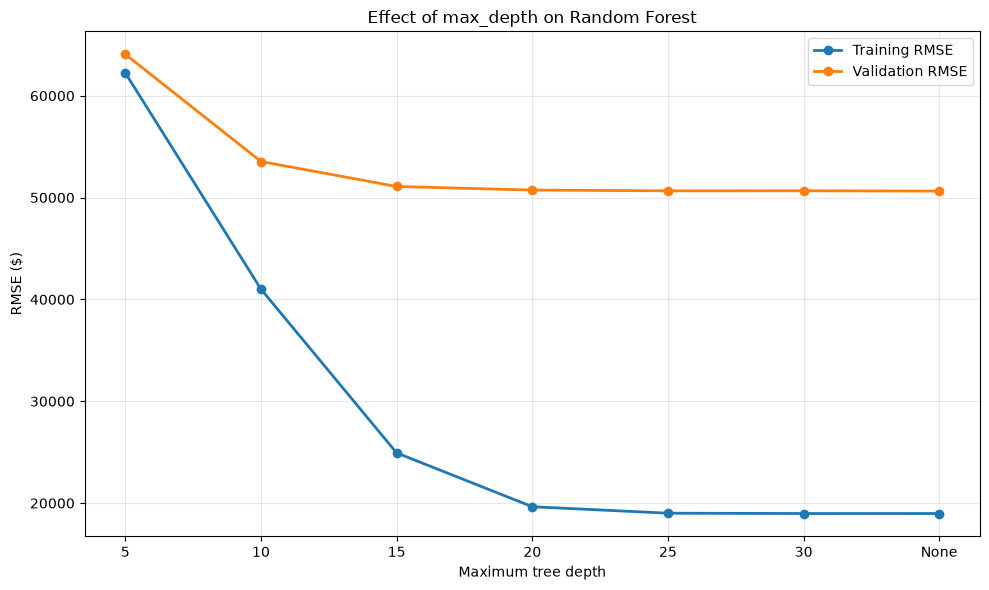

In [35]:
import matplotlib.pyplot as plt


plot_results = depth_results_df.copy()

plot_results["max_depth_label"] = (
    plot_results["max_depth"].astype(str)
)

plt.figure(figsize=(10, 6))

plt.plot(
    plot_results["max_depth_label"],
    plot_results["train_rmse"],
    marker="o",
    linewidth=2,
    label="Training RMSE",
)

plt.plot(
    plot_results["max_depth_label"],
    plot_results["validation_rmse"],
    marker="o",
    linewidth=2,
    label="Validation RMSE",
)

plt.xlabel("Maximum tree depth")
plt.ylabel("RMSE ($)")
plt.title("Effect of max_depth on Random Forest")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

> **After original cell 037:** Good plot. It helps explain why very deep trees can overfit.


> **Before original cell 038:** Test `min_samples_leaf` as a Random Forest regularization parameter.


In [36]:
from sklearn.base import clone
from sklearn.model_selection import cross_validate
import pandas as pd


min_samples_leaf_values = [
    1,
    2,
    3,
    4,
    5,
    8,
    10,
    15,
    20,
]

leaf_results = []

for leaf_size in min_samples_leaf_values:

    experiment_model = clone(rf_baseline)

    experiment_model.set_params(
        model__max_depth=20,
        model__min_samples_leaf=leaf_size,
        model__min_samples_split=2,
    )

    scores = cross_validate(
        estimator=experiment_model,
        X=X_train,
        y=y_train,
        scoring={
            "rmse": "neg_root_mean_squared_error",
            "mae": "neg_mean_absolute_error",
            "r2": "r2",
        },
        cv=cv,
        n_jobs=-1,
        return_train_score=True,
    )

    train_rmse = -scores["train_rmse"].mean()
    validation_rmse = -scores["test_rmse"].mean()

    leaf_results.append({
        "min_samples_leaf": leaf_size,
        "train_rmse": train_rmse,
        "validation_rmse": validation_rmse,
        "validation_rmse_std": (
            -scores["test_rmse"]
        ).std(),
        "rmse_gap": validation_rmse - train_rmse,
        "validation_mae": (
            -scores["test_mae"].mean()
        ),
        "validation_r2": scores["test_r2"].mean(),
    })


leaf_results_df = pd.DataFrame(leaf_results)

leaf_results_df.round({
    "train_rmse": 2,
    "validation_rmse": 2,
    "validation_rmse_std": 2,
    "rmse_gap": 2,
    "validation_mae": 2,
    "validation_r2": 4,
})

,min_samples_leaf,train_rmse,validation_rmse,validation_rmse_std,rmse_gap,validation_mae,validation_r2
0,1,19644.88,50736.05,923.49,31091.18,33057.18,0.8076
1,2,24084.53,50666.21,1021.98,26581.68,33014.06,0.8081
2,3,28342.27,50727.51,1026.08,22385.25,33027.54,0.8076
3,4,31708.11,50896.75,1047.52,19188.64,33193.24,0.8063
4,5,34314.16,51079.53,1040.20,16765.38,33348.84,0.8050
5,8,39477.24,51741.69,1069.19,12264.45,33939.99,0.7999
6,10,41748.26,52209.73,1022.29,10461.47,34338.86,0.7962
7,15,45435.07,53125.42,1090.73,7690.36,35169.43,0.7890
8,20,47717.82,53920.51,1168.44,6202.69,35923.73,0.7827


> **After original cell 038:** Good experiment. Leaf size controls how small the final tree groups are allowed to become.


> **Before original cell 039:** Sort the leaf-size experiment by validation RMSE.


In [37]:
leaf_results_df.sort_values(
    by="validation_rmse"
).round(2)

,min_samples_leaf,train_rmse,validation_rmse,validation_rmse_std,rmse_gap,validation_mae,validation_r2
1,2,24084.53,50666.21,1021.98,26581.68,33014.06,0.81
2,3,28342.27,50727.51,1026.08,22385.25,33027.54,0.81
0,1,19644.88,50736.05,923.49,31091.18,33057.18,0.81
3,4,31708.11,50896.75,1047.52,19188.64,33193.24,0.81
4,5,34314.16,51079.53,1040.20,16765.38,33348.84,0.80
5,8,39477.24,51741.69,1069.19,12264.45,33939.99,0.80
6,10,41748.26,52209.73,1022.29,10461.47,34338.86,0.80
7,15,45435.07,53125.42,1090.73,7690.36,35169.43,0.79
8,20,47717.82,53920.51,1168.44,6202.69,35923.73,0.78


> **After original cell 039:** Correct. This identifies the useful leaf-size region before joint tuning.


> **Before original cell 040:** Plot how `min_samples_leaf` changes training and validation error.


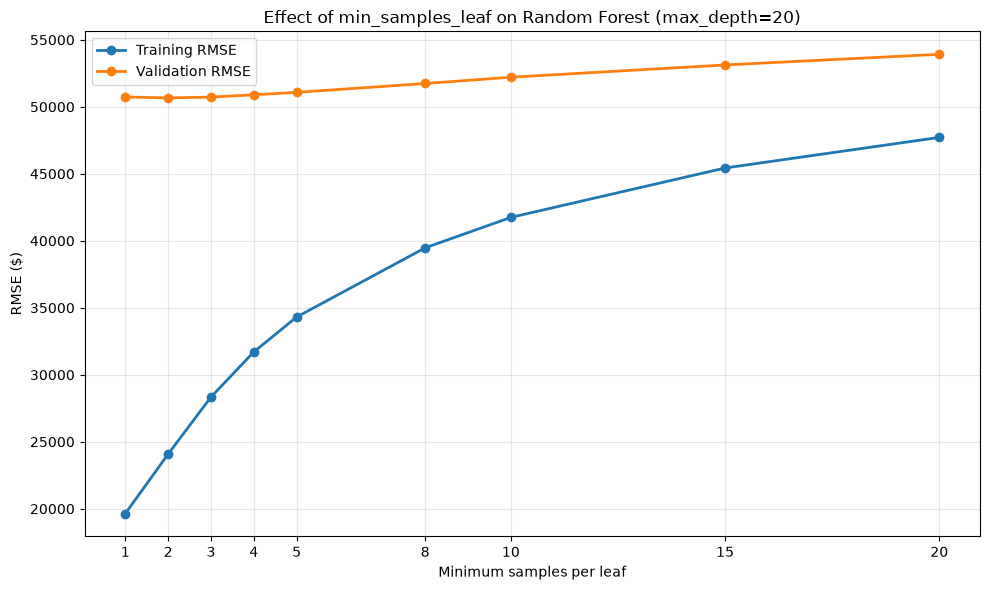

In [38]:
import matplotlib.pyplot as plt


plt.figure(figsize=(10, 6))

plt.plot(
    leaf_results_df["min_samples_leaf"],
    leaf_results_df["train_rmse"],
    marker="o",
    linewidth=2,
    label="Training RMSE",
)

plt.plot(
    leaf_results_df["min_samples_leaf"],
    leaf_results_df["validation_rmse"],
    marker="o",
    linewidth=2,
    label="Validation RMSE",
)

plt.xlabel("Minimum samples per leaf")
plt.ylabel("RMSE ($)")
plt.title(
    "Effect of min_samples_leaf "
    "on Random Forest (max_depth=20)"
)
plt.xticks(min_samples_leaf_values)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

> **After original cell 040:** Good visualization. It shows where extra regularization begins to underfit.


> **Before original cell 041:** Record provisional choices from the depth and leaf experiments.


In [39]:
max_depth = 20
min_samples_leaf = 2

> **After original cell 041:** Useful checkpoint. These variables are notes unless later cells explicitly use them.


> **Before original cell 042:** Test `max_features`, which controls feature randomness at each split.


In [40]:
from sklearn.base import clone
from sklearn.model_selection import cross_validate
import pandas as pd


max_features_values = [
    0.3,
    0.4,
    0.5,
    0.6,
    0.7,
    0.8,
    1.0,
    "sqrt",
]

feature_results = []

for max_features_value in max_features_values:

    experiment_model = clone(rf_baseline)

    experiment_model.set_params(
        model__max_depth=20,
        model__min_samples_leaf=2,
        model__min_samples_split=2,
        model__max_features=max_features_value,
    )

    scores = cross_validate(
        estimator=experiment_model,
        X=X_train,
        y=y_train,
        scoring={
            "rmse": "neg_root_mean_squared_error",
            "mae": "neg_mean_absolute_error",
            "r2": "r2",
        },
        cv=cv,
        n_jobs=-1,
        return_train_score=True,
    )

    train_rmse = -scores["train_rmse"].mean()
    validation_rmse = -scores["test_rmse"].mean()

    feature_results.append({
        "max_features": max_features_value,
        "train_rmse": train_rmse,
        "validation_rmse": validation_rmse,
        "validation_rmse_std": (
            -scores["test_rmse"]
        ).std(),
        "rmse_gap": validation_rmse - train_rmse,
        "validation_mae": (
            -scores["test_mae"]
        ).mean(),
        "validation_r2": scores["test_r2"].mean(),
    })


feature_results_df = pd.DataFrame(feature_results)

feature_results_df.round({
    "train_rmse": 2,
    "validation_rmse": 2,
    "validation_rmse_std": 2,
    "rmse_gap": 2,
    "validation_mae": 2,
    "validation_r2": 4,
})

,max_features,train_rmse,validation_rmse,validation_rmse_std,rmse_gap,validation_mae,validation_r2
0,0.3,26271.25,49908.78,978.64,23637.52,33371.07,0.8138
1,0.4,25008.17,49352.99,1182.03,24344.82,32632.12,0.8179
2,0.5,24560.81,49519.70,884.52,24958.90,32540.11,0.8167
3,0.6,24318.57,49582.84,1020.57,25264.27,32501.03,0.8162
4,0.7,24170.67,49794.27,934.05,25623.60,32564.19,0.8146
5,0.8,24125.86,50080.93,988.89,25955.07,32692.89,0.8125
6,1.0,24084.53,50666.21,1021.98,26581.68,33014.06,0.8081
7,sqrt,26514.30,50111.24,1065.68,23596.94,33566.32,0.8123


> **After original cell 042:** Strong diagnostic. This parameter meaningfully improved validation performance by making trees more diverse.


> **Before original cell 043:** Sort the `max_features` experiment by validation RMSE.


In [41]:
feature_results_df.sort_values(
    by="validation_rmse"
).round(2)

,max_features,train_rmse,validation_rmse,validation_rmse_std,rmse_gap,validation_mae,validation_r2
1,0.4,25008.17,49352.99,1182.03,24344.82,32632.12,0.82
2,0.5,24560.81,49519.70,884.52,24958.90,32540.11,0.82
3,0.6,24318.57,49582.84,1020.57,25264.27,32501.03,0.82
4,0.7,24170.67,49794.27,934.05,25623.60,32564.19,0.81
0,0.3,26271.25,49908.78,978.64,23637.52,33371.07,0.81
5,0.8,24125.86,50080.93,988.89,25955.07,32692.89,0.81
7,sqrt,26514.30,50111.24,1065.68,23596.94,33566.32,0.81
6,1.0,24084.53,50666.21,1021.98,26581.68,33014.06,0.81


> **After original cell 043:** Correct. This exposes the best feature-randomness region.


> **Before original cell 044:** Plot the impact of `max_features` on train and validation RMSE.


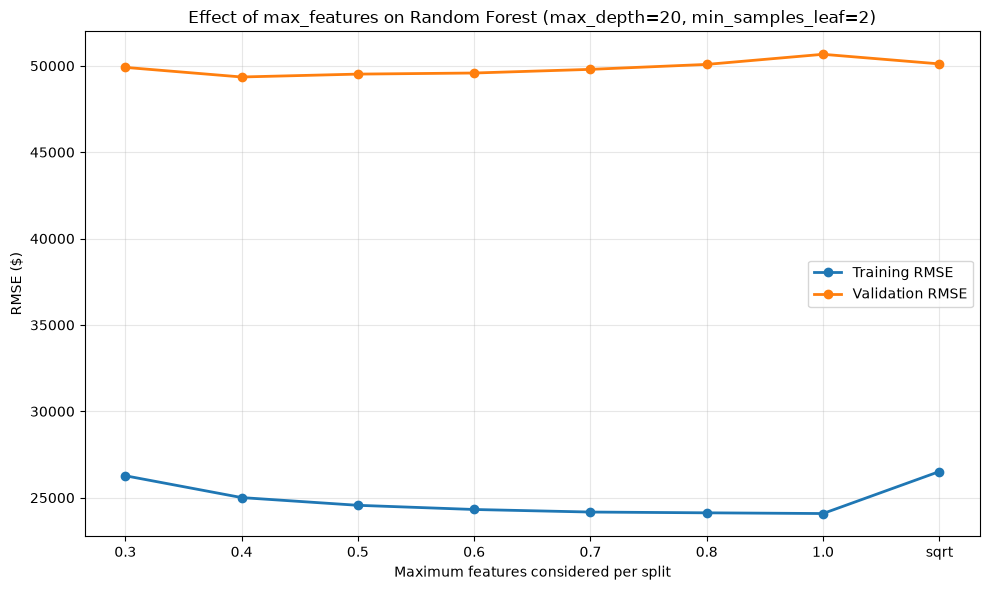

In [42]:
import matplotlib.pyplot as plt


plot_df = feature_results_df.copy()
plot_df["max_features_label"] = (
    plot_df["max_features"].astype(str)
)

plt.figure(figsize=(10, 6))

plt.plot(
    plot_df["max_features_label"],
    plot_df["train_rmse"],
    marker="o",
    linewidth=2,
    label="Training RMSE",
)

plt.plot(
    plot_df["max_features_label"],
    plot_df["validation_rmse"],
    marker="o",
    linewidth=2,
    label="Validation RMSE",
)

plt.xlabel("Maximum features considered per split")
plt.ylabel("RMSE ($)")
plt.title(
    "Effect of max_features on Random Forest "
    "(max_depth=20, min_samples_leaf=2)"
)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

> **After original cell 044:** Good explanation plot. It shows why allowing every split to see all features can make trees too similar.


> **Before original cell 045:** Record provisional settings before testing `min_samples_split`.


In [43]:
max_depth = 20
min_samples_leaf = 2
max_features = 0.4

> **After original cell 045:** Good checkpoint before the next controlled experiment.


> **Before original cell 046:** Test the minimum number of samples required before a node can split.


In [44]:
from sklearn.base import clone
from sklearn.model_selection import cross_validate
import pandas as pd


min_samples_split_values = [
    2,
    4,
    6,
    8,
    10,
    15,
    20,
    30,
    40,
]

split_results = []

for split_size in min_samples_split_values:

    experiment_model = clone(rf_baseline)

    experiment_model.set_params(
        model__max_depth=20,
        model__min_samples_leaf=2,
        model__min_samples_split=split_size,
        model__max_features=0.4,
    )

    scores = cross_validate(
        estimator=experiment_model,
        X=X_train,
        y=y_train,
        scoring={
            "rmse": "neg_root_mean_squared_error",
            "mae": "neg_mean_absolute_error",
            "r2": "r2",
        },
        cv=cv,
        n_jobs=-1,
        return_train_score=True,
    )

    train_rmse = -scores["train_rmse"].mean()
    validation_rmse = -scores["test_rmse"].mean()

    split_results.append({
        "min_samples_split": split_size,
        "train_rmse": train_rmse,
        "validation_rmse": validation_rmse,
        "validation_rmse_std": (
            -scores["test_rmse"]
        ).std(),
        "rmse_gap": validation_rmse - train_rmse,
        "validation_mae": (
            -scores["test_mae"]
        ).mean(),
        "validation_r2": scores["test_r2"].mean(),
    })


split_results_df = pd.DataFrame(split_results)

split_results_df.round({
    "train_rmse": 2,
    "validation_rmse": 2,
    "validation_rmse_std": 2,
    "rmse_gap": 2,
    "validation_mae": 2,
    "validation_r2": 4,
})

,min_samples_split,train_rmse,validation_rmse,validation_rmse_std,rmse_gap,validation_mae,validation_r2
0,2,25008.17,49352.99,1182.03,24344.82,32632.12,0.8179
1,4,25008.17,49352.99,1182.03,24344.82,32632.12,0.8179
2,6,27346.24,49481.00,1088.51,22134.76,32695.96,0.8170
3,8,29478.50,49518.31,1040.90,20039.81,32810.73,0.8167
4,10,31238.54,49641.50,1028.69,18402.97,32939.92,0.8158
5,15,34572.46,50042.68,1120.80,15470.22,33308.34,0.8128
6,20,36906.90,50399.05,1123.03,13492.16,33691.22,0.8101
7,30,40276.36,50957.08,1136.66,10680.72,34218.56,0.8059
8,40,42631.58,51622.94,1040.38,8991.36,34832.42,0.8008


> **After original cell 046:** Good experiment. It confirms this parameter has a smaller effect when `min_samples_leaf` is already controlled.


> **Before original cell 047:** Sort `min_samples_split` results by validation RMSE.


In [45]:
split_results_df.sort_values(
    by="validation_rmse"
).round(2)

,min_samples_split,train_rmse,validation_rmse,validation_rmse_std,rmse_gap,validation_mae,validation_r2
0,2,25008.17,49352.99,1182.03,24344.82,32632.12,0.82
1,4,25008.17,49352.99,1182.03,24344.82,32632.12,0.82
2,6,27346.24,49481.00,1088.51,22134.76,32695.96,0.82
3,8,29478.50,49518.31,1040.90,20039.81,32810.73,0.82
4,10,31238.54,49641.50,1028.69,18402.97,32939.92,0.82
5,15,34572.46,50042.68,1120.80,15470.22,33308.34,0.81
6,20,36906.90,50399.05,1123.03,13492.16,33691.22,0.81
7,30,40276.36,50957.08,1136.66,10680.72,34218.56,0.81
8,40,42631.58,51622.94,1040.38,8991.36,34832.42,0.80


> **After original cell 047:** Correct. Small values perform best in this notebook.


> **Before original cell 048:** Visualize the effect of `min_samples_split`.


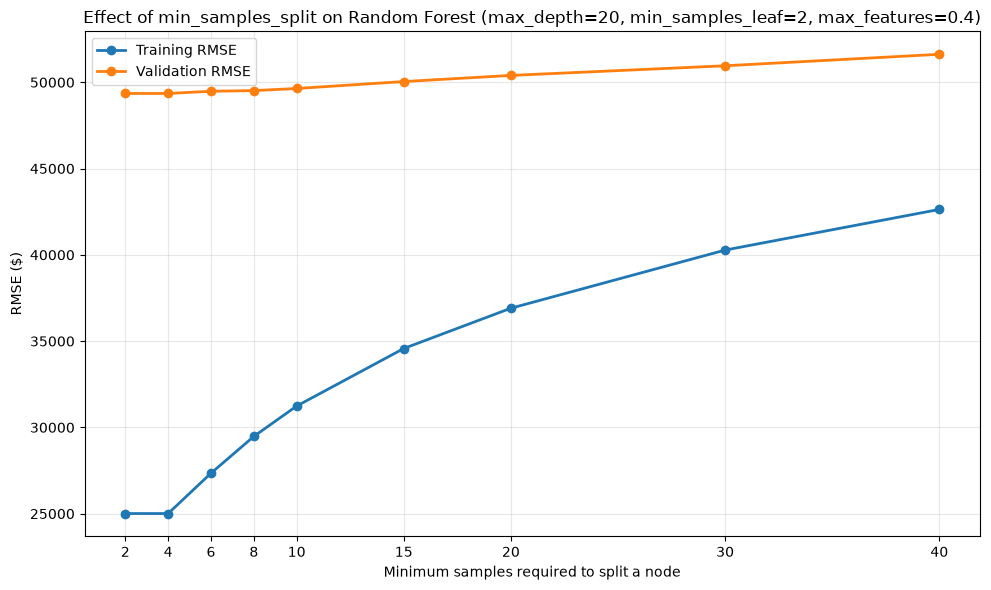

In [46]:
import matplotlib.pyplot as plt


plt.figure(figsize=(10, 6))

plt.plot(
    split_results_df["min_samples_split"],
    split_results_df["train_rmse"],
    marker="o",
    linewidth=2,
    label="Training RMSE",
)

plt.plot(
    split_results_df["min_samples_split"],
    split_results_df["validation_rmse"],
    marker="o",
    linewidth=2,
    label="Validation RMSE",
)

plt.xlabel("Minimum samples required to split a node")
plt.ylabel("RMSE ($)")
plt.title(
    "Effect of min_samples_split on Random Forest "
    "(max_depth=20, min_samples_leaf=2, max_features=0.4)"
)
plt.xticks(min_samples_split_values)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

> **After original cell 048:** Good plot. It shows that very large split values restrict the model too much.


> **Before original cell 049:** Record the final controlled-diagnosis configuration before joint search.


In [47]:
max_depth = 20
min_samples_leaf = 2
max_features = 0.4
min_samples_split = 4


> **After original cell 049:** Good transition point. I also cleaned the assignment formatting.


> **Before original cell 050:** Define the RandomizedSearchCV parameter space from the earlier experiments.


In [48]:
from scipy.stats import randint, uniform
from sklearn.model_selection import RandomizedSearchCV


parameter_distributions = {
    # More trees improve stability, although they usually
    # do not solve overfitting by themselves.
    "model__n_estimators": randint(200, 601),

    # Supported by the max_depth experiment.
    # None remains included because leaf and feature
    # regularization may make deeper trees useful.
    "model__max_depth": [
        15,
        18,
        20,
        22,
        25,
        30,
        None,
    ],

    # Supported by the leaf-size experiment.
    "model__min_samples_leaf": [
        1,
        2,
        3,
        4,
    ],

    # Values above 10 did not help.
    "model__min_samples_split": [
        2,
        4,
        6,
        8,
        10,
    ],

    # Samples continuous values from 0.30 up to 0.60.
    "model__max_features": uniform(
        loc=0.30,
        scale=0.30,
    ),
}

> **After original cell 050:** Strong approach. The search space is evidence-based instead of random guessing.


> **Before original cell 051:** Run randomized search to tune multiple interacting hyperparameters together.


In [ ]:
random_search = RandomizedSearchCV(
    estimator=rf_baseline,
    param_distributions=parameter_distributions,
    n_iter=40,

    scoring=scoring,
    refit="rmse",

    cv=cv,
    n_jobs=-1,

    random_state=42,
    return_train_score=True,

    verbose=2,
    error_score="raise",
)

random_search.fit(
    X_train,
    y_train,
)

Fitting 5 folds for each of 40 candidates, totalling 200 fits
[CV] END model__max_depth=25, model__max_features=0.4790550473839461, model__min_samples_leaf=2, model__min_samples_split=6, model__n_estimators=414; total time=  11.8s
[CV] END model__max_depth=20, model__max_features=0.3061753482887407, model__min_samples_leaf=2, model__min_samples_split=8, model__n_estimators=493; total time=   8.7s


/Users/danish_ansari/Projects/hand-on-ml-practice/.venv/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


[CV] END model__max_depth=None, model__max_features=0.5389628960580698, model__min_samples_leaf=3, model__min_samples_split=6, model__n_estimators=271; total time=   8.2s
[CV] END model__max_depth=20, model__max_features=0.43777466758976014, model__min_samples_leaf=1, model__min_samples_split=8, model__n_estimators=559; total time=  14.9s
[CV] END model__max_depth=None, model__max_features=0.5389628960580698, model__min_samples_leaf=3, model__min_samples_split=6, model__n_estimators=271; total time=   8.1s
[CV] END model__max_depth=20, model__max_features=0.43777466758976014, model__min_samples_leaf=1, model__min_samples_split=8, model__n_estimators=559; total time=  16.4s
[CV] END model__max_depth=30, model__max_features=0.30211989156591523, model__min_samples_leaf=1, model__min_samples_split=2, model__n_estimators=258; total time=   5.7s
[CV] END model__max_depth=25, model__max_features=0.4790550473839461, model__min_samples_leaf=2, model__min_samples_split=6, model__n_estimators=414

> **After original cell 051:** Good joint tuning step. For a polished GitHub notebook, you can clear long verbose logs or set `verbose=0` before rerunning.


> **Before original cell 052:** Display the best randomized search configuration and validation metrics.


In [ ]:
best_index = random_search.best_index_

best_cv_train_rmse = (
    -random_search.cv_results_[
        "mean_train_rmse"
    ][best_index]
)

best_cv_validation_rmse = (
    -random_search.best_score_
)

best_cv_mae = (
    -random_search.cv_results_[
        "mean_test_mae"
    ][best_index]
)

best_cv_r2 = (
    random_search.cv_results_[
        "mean_test_r2"
    ][best_index]
)

best_rmse_gap = (
    best_cv_validation_rmse -
    best_cv_train_rmse
)


print("Best parameters")
print("-" * 50)

for parameter, value in random_search.best_params_.items():
    print(f"{parameter}: {value}")


print("\nBest cross-validation performance")
print("-" * 50)

print(
    f"Training RMSE   : "
    f"${best_cv_train_rmse:,.2f}"
)

print(
    f"Validation RMSE : "
    f"${best_cv_validation_rmse:,.2f}"
)

print(
    f"Validation MAE  : "
    f"${best_cv_mae:,.2f}"
)

print(
    f"Validation R²   : "
    f"{best_cv_r2:.4f}"
)

print(
    f"RMSE gap        : "
    f"${best_rmse_gap:,.2f}"
)

> **After original cell 052:** Good summary. Validation RMSE improved, although the train-validation gap remains high.


> **Before original cell 053:** Inspect the top ten randomized-search configurations.


In [ ]:
search_results = pd.DataFrame(
    random_search.cv_results_
)

search_summary = pd.DataFrame({
    "rank": search_results["rank_test_rmse"],

    "max_depth":
        search_results[
            "param_model__max_depth"
        ],

    "min_samples_leaf":
        search_results[
            "param_model__min_samples_leaf"
        ],

    "min_samples_split":
        search_results[
            "param_model__min_samples_split"
        ],

    "max_features":
        search_results[
            "param_model__max_features"
        ],

    "n_estimators":
        search_results[
            "param_model__n_estimators"
        ],

    "train_rmse":
        -search_results[
            "mean_train_rmse"
        ],

    "validation_rmse":
        -search_results[
            "mean_test_rmse"
        ],

    "validation_rmse_std":
        search_results[
            "std_test_rmse"
        ],

    "validation_mae":
        -search_results[
            "mean_test_mae"
        ],

    "validation_r2":
        search_results[
            "mean_test_r2"
        ],
})

search_summary["rmse_gap"] = (
    search_summary["validation_rmse"] -
    search_summary["train_rmse"]
)

top_10_results = (
    search_summary
    .sort_values("rank")
    .head(10)
)

top_10_results.round({
    "max_features": 3,
    "train_rmse": 2,
    "validation_rmse": 2,
    "validation_rmse_std": 2,
    "validation_mae": 2,
    "validation_r2": 4,
    "rmse_gap": 2,
})

> **After original cell 053:** Excellent practice. Looking beyond rank 1 helps define a better final grid.


> **Before original cell 054:** Quantify randomized-search improvement over the baseline model.


In [ ]:
baseline_cv_rmse = (
    cv_summary["validation_rmse"].mean()
)

rmse_improvement = (
    baseline_cv_rmse -
    best_cv_validation_rmse
)

improvement_percentage = (
    rmse_improvement /
    baseline_cv_rmse
) * 100


print(
    f"Baseline CV RMSE : "
    f"${baseline_cv_rmse:,.2f}"
)

print(
    f"Optimized CV RMSE: "
    f"${best_cv_validation_rmse:,.2f}"
)

print(
    f"Improvement      : "
    f"${rmse_improvement:,.2f} "
    f"({improvement_percentage:.2f}%)"
)

> **After original cell 054:** Good result: validation RMSE improved by $1,473.89, or 2.91%.


> **Before original cell 055:** Record the rank-1 randomized-search parameters.


In [ ]:
max_depth = 25
min_samples_leaf = 1
min_samples_split = 2
max_features = 0.541
n_estimators = 526


> **After original cell 055:** Useful note, but these standalone variables are not used later by the grid search.


> **Before original cell 056:** Define a small final grid around promising regions from randomized search.


In [ ]:
from sklearn.model_selection import GridSearchCV


final_parameter_grid = {
    # Fixed because the top configurations used roughly
    # 500–600 trees, and further fine-tuning is unlikely
    # to provide a meaningful improvement.
    "model__n_estimators": [550],

    # Promising depths from the top-ranked configurations.
    "model__max_depth": [18, 22, 25],

    # Compare the high-complexity and regularized regions.
    "model__min_samples_leaf": [1, 2],

    # Most useful split values from the top results.
    "model__min_samples_split": [2, 6],

    # Neighbourhoods found by RandomizedSearchCV.
    "model__max_features": [
        0.35,
        0.42,
        0.48,
        0.54,
    ],
}

> **After original cell 056:** Good focused grid. It balances compute time with a reasonable final refinement.


> **Before original cell 057:** Run the final exhaustive grid search.


In [ ]:
final_grid_search = GridSearchCV(
    estimator=rf_baseline,
    param_grid=final_parameter_grid,

    scoring=scoring,
    refit="rmse",

    cv=cv,
    n_jobs=-1,

    return_train_score=True,
    verbose=2,
    error_score="raise",
)

final_grid_search.fit(
    X_train,
    y_train,
)

> **After original cell 057:** Good final tuning step. After this, the test set should be used only once.


> **Before original cell 058:** Display the best grid-search parameters and cross-validation performance.


In [ ]:
grid_best_index = final_grid_search.best_index_

grid_best_train_rmse = -final_grid_search.cv_results_[
    "mean_train_rmse"
][grid_best_index]

grid_best_validation_rmse = -final_grid_search.best_score_

grid_best_validation_std = final_grid_search.cv_results_[
    "std_test_rmse"
][grid_best_index]

grid_best_validation_mae = -final_grid_search.cv_results_[
    "mean_test_mae"
][grid_best_index]

grid_best_validation_r2 = final_grid_search.cv_results_[
    "mean_test_r2"
][grid_best_index]

grid_best_gap = (
    grid_best_validation_rmse -
    grid_best_train_rmse
)


print("Best Grid Search Parameters")
print("-" * 50)

for parameter, value in final_grid_search.best_params_.items():
    print(f"{parameter}: {value}")


print("\nBest Grid Search Performance")
print("-" * 50)

print(f"Training RMSE       : ${grid_best_train_rmse:,.2f}")
print(f"Validation RMSE     : ${grid_best_validation_rmse:,.2f}")
print(f"Validation RMSE std : ${grid_best_validation_std:,.2f}")
print(f"Validation MAE      : ${grid_best_validation_mae:,.2f}")
print(f"Validation R²       : {grid_best_validation_r2:.4f}")
print(f"RMSE gap            : ${grid_best_gap:,.2f}")

> **After original cell 058:** Best validation RMSE is $49,013.53, a small improvement over randomized search.


> **Before original cell 059:** Compare baseline, randomized search, and final grid search in one table.


In [ ]:
model_comparison = pd.DataFrame({
    "stage": [
        "Baseline Random Forest",
        "Randomized Search",
        "Final Grid Search",
    ],
    "validation_rmse": [
        baseline_cv_rmse,
        best_cv_validation_rmse,
        grid_best_validation_rmse,
    ],
})

model_comparison["improvement_vs_baseline"] = (
    baseline_cv_rmse -
    model_comparison["validation_rmse"]
)

model_comparison["improvement_percentage"] = (
    model_comparison["improvement_vs_baseline"] /
    baseline_cv_rmse
) * 100

model_comparison.round(2)

> **After original cell 059:** Good project summary. It clearly shows the final 3.20% improvement and diminishing returns.


> **Before original cell 060:** Evaluate the selected final model on the untouched test set.


In [ ]:
from sklearn.metrics import (
    root_mean_squared_error,
    mean_absolute_error,
    r2_score,
)

final_model = final_grid_search.best_estimator_

test_predictions = final_model.predict(X_test)

test_rmse = root_mean_squared_error(
    y_test,
    test_predictions
)

test_mae = mean_absolute_error(
    y_test,
    test_predictions
)

test_r2 = r2_score(
    y_test,
    test_predictions
)

print("Final Test Set Performance")
print("-" * 40)
print(f"Test RMSE: ${test_rmse:,.2f}")
print(f"Test MAE : ${test_mae:,.2f}")
print(f"Test R²  : {test_r2:.4f}")

> **After original cell 060:** Correct final exam step. Test RMSE is $46,737.40, close to validation and slightly better.


> **Before original cell 061:** Create a compact validation-versus-test comparison table.


In [ ]:
final_summary = pd.DataFrame({
    "metric": [
        "Validation RMSE",
        "Test RMSE",
        "Validation MAE",
        "Test MAE",
        "Validation R²",
        "Test R²",
    ],
    "value": [
        grid_best_validation_rmse,
        test_rmse,
        grid_best_validation_mae,
        test_mae,
        grid_best_validation_r2,
        test_r2,
    ],
})

final_summary

> **After original cell 061:** Good final performance table. It makes generalization easy to explain.


> **Before original cell 062:** Write the final project conclusion in portfolio language.


## Final Model Conclusion

The final Random Forest model completed the full end-to-end machine learning workflow: data loading, train/test split, preprocessing, baseline modeling, cross-validation, hyperparameter tuning, final test evaluation, error analysis, feature importance, and model saving.

### Final performance

| Metric | Validation | Test |
|---|---:|---:|
| RMSE | $49,013.53 | $46,737.40 |
| MAE | $32,354.32 | $31,219.36 |
| R2 | 0.8204 | 0.8324 |

The test performance is close to the cross-validation performance, and the test score is slightly better than validation. This suggests that the model generalizes well to unseen data and did not collapse on the untouched test set.

Compared with the baseline Random Forest, hyperparameter tuning improved validation RMSE by approximately 3.2%.

### Error analysis summary

The model performs best on low-to-mid value houses and shows weaker performance at the price extremes. It tends to overpredict lower-value houses and underpredict higher-value houses. The largest errors occur for expensive houses, especially in the 400K-500K range.

### Feature importance summary

Permutation feature importance shows that `median_income` is the strongest predictor. Location-related features such as `ocean_proximity`, `longitude`, and `latitude` also contribute meaningfully. Size and density features such as `total_rooms`, `population`, and `households` are also useful, but they should be interpreted carefully because they may be correlated.

### Limitation

The model strongly underpredicts many high-value houses. One reason is that the California housing target contains capped values near 500,001, which makes expensive houses harder to model accurately. Real-world house prices also depend on factors that are not fully captured in this dataset, such as exact neighborhood quality, school ratings, renovation status, and local market conditions.


> **After original cell 062:** The conclusion now covers final metrics, validation-vs-test comparison, error analysis, feature importance, and the high-value-house limitation.


> **Before original cell 063:** Create a row-level error analysis table from test predictions.


In [ ]:
error_analysis = X_test.copy()

error_analysis["actual_value"] = y_test
error_analysis["predicted_value"] = test_predictions

error_analysis["error"] = (
    error_analysis["predicted_value"] -
    error_analysis["actual_value"]
)

error_analysis["absolute_error"] = (
    error_analysis["error"].abs()
)

error_analysis["absolute_percentage_error"] = (
    error_analysis["absolute_error"] /
    error_analysis["actual_value"]
) * 100

error_analysis.head()

> **After original cell 063:** Excellent. This moves the notebook from only reporting scores to diagnosing model behavior.


> **Before original cell 064:** Inspect the worst individual predictions by absolute error.


In [ ]:
worst_predictions = (
    error_analysis
    .sort_values("absolute_error", ascending=False)
    .head(20)
)

worst_predictions[
    [
        "actual_value",
        "predicted_value",
        "error",
        "absolute_error",
        "absolute_percentage_error",
        "median_income",
        "ocean_proximity",
        "longitude",
        "latitude",
    ]
].round(2)

> **After original cell 064:** Good diagnostic. These rows show where the model fails most severely.


> **Before original cell 065:** Summarize the distribution of absolute errors.


In [ ]:
error_analysis["absolute_error"].describe().round(2)

> **After original cell 065:** Useful. Error percentiles give more context than a single MAE or RMSE value.


> **Before original cell 066:** Plot actual values against predicted values with a perfect-prediction reference line.


In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    error_analysis["actual_value"],
    error_analysis["predicted_value"],
    alpha=0.35
)

plt.plot(
    [0, 500000],
    [0, 500000],
    color="red",
    linewidth=2
)

plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")
plt.title("Actual vs Predicted House Values")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

> **After original cell 066:** Good visual check. Points far from the red line represent large errors.


> **Before original cell 067:** Group prediction errors by ocean proximity.


In [ ]:
error_by_ocean = (
    error_analysis
    .groupby("ocean_proximity")
    .agg(
        count=("absolute_error", "count"),
        mean_absolute_error=("absolute_error", "mean"),
        median_absolute_error=("absolute_error", "median"),
        mean_actual_value=("actual_value", "mean"),
    )
    .sort_values("mean_absolute_error", ascending=False)
)

error_by_ocean.round(2)

> **After original cell 067:** Good segment analysis. Be careful with `ISLAND` because it has only 3 test records.


> **Before original cell 068:** Group errors by actual house-value range.


In [ ]:
error_analysis["value_range"] = pd.cut(
    error_analysis["actual_value"],
    bins=[0, 100000, 200000, 300000, 400000, 500001],
    labels=[
        "0-100K",
        "100K-200K",
        "200K-300K",
        "300K-400K",
        "400K-500K",
    ],
    include_lowest=True,
)

error_by_value_range = (
    error_analysis
    .groupby("value_range", observed=False)
    .agg(
        count=("absolute_error", "count"),
        mean_absolute_error=("absolute_error", "mean"),
        median_absolute_error=("absolute_error", "median"),
        mean_actual_value=("actual_value", "mean"),
        mean_predicted_value=("predicted_value", "mean"),
    )
)

error_by_value_range.round(2)

> **After original cell 068:** Important finding. Error rises sharply for expensive houses.


> **Before original cell 069:** Plot mean absolute error by house-value range.


In [ ]:
error_by_value_range["mean_absolute_error"].plot(
    kind="bar",
    figsize=(9, 5),
    title="Mean Absolute Error by Actual House Value Range",
    ylabel="Mean Absolute Error ($)",
    xlabel="Actual House Value Range",
    grid=True,
)

plt.tight_layout()
plt.show()

> **After original cell 069:** Good portfolio-friendly chart. It makes the high-value weakness visually clear.


> **Before original cell 070:** Check prediction bias by value range using signed mean error.


In [ ]:
value_range_bias = (
    error_analysis
    .groupby("value_range", observed=False)
    .agg(
        count=("absolute_error", "count"),
        mean_actual_value=("actual_value", "mean"),
        mean_predicted_value=("predicted_value", "mean"),
        mean_error=("error", "mean"),
        mean_absolute_error=("absolute_error", "mean"),
        mean_absolute_percentage_error=(
            "absolute_percentage_error",
            "mean"
        ),
    )
)

value_range_bias.round(2)

> **After original cell 070:** Strong diagnosis. The model overpredicts cheap houses and underpredicts expensive houses.


> **Before original cell 071:** Investigate records where the target is capped at 500001.


In [ ]:
cap_value = 500001

capped_houses = error_analysis[
    error_analysis["actual_value"] >= cap_value
]

print("Number of capped test records:", len(capped_houses))

capped_houses[
    [
        "actual_value",
        "predicted_value",
        "error",
        "absolute_error",
        "median_income",
        "ocean_proximity",
        "longitude",
        "latitude",
    ]
].sort_values(
    "absolute_error",
    ascending=False
).head(20).round(2)

> **After original cell 071:** Good limitation check. The capped records help explain large high-value errors.


> **Before original cell 072:** Summarize the error-analysis findings in words.


## Error Analysis Finding

The final model performs best on mid-value houses and shows weaker performance at the price extremes.

For low-value houses, the model tends to overpredict. For high-value houses, especially in the 400K-500K range, the model strongly underpredicts. This suggests that the model is pulling predictions toward the middle of the target distribution.

The highest absolute errors occur for expensive houses. This may be partly because the California housing dataset contains capped house values near 500,001, making high-value houses harder to model accurately.

> **After original cell 072:** Good explanation. This is useful for GitHub or portfolio readers.


> **Before original cell 073:** Compute permutation feature importance on the final pipeline.


In [ ]:
from sklearn.inspection import permutation_importance
import pandas as pd

feature_importance = permutation_importance(
    final_model,
    X_test,
    y_test,
    scoring="neg_root_mean_squared_error",
    n_repeats=10,
    random_state=42,
    n_jobs=-1,
)

importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": feature_importance.importances_mean,
    "importance_std": feature_importance.importances_std,
}).sort_values("importance_mean", ascending=False)

importance_df.round(4)

> **After original cell 073:** Good choice. Permutation importance works with the full pipeline and keeps results tied to original input columns.


> **Before original cell 074:** Plot permutation feature importance.


In [ ]:
plt.figure(figsize=(9, 6))

plt.barh(
    importance_df["feature"],
    importance_df["importance_mean"]
)

plt.xlabel("Increase in RMSE when feature is shuffled")
plt.title("Permutation Feature Importance")
plt.gca().invert_yaxis()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

> **After original cell 074:** Good plot. It clearly shows `median_income` as the dominant predictor.


> **Before original cell 075:** Summarize feature-importance findings.


## Feature Importance Finding

Permutation feature importance shows that `median_income` is the most important predictor for the final Random Forest model. Location-related variables such as `ocean_proximity`, `longitude`, and `latitude` also contribute meaningfully.

The model also uses area-size and density-related features such as `total_rooms`, `population`, and `households`. These features should be interpreted carefully because they may be correlated with each other.

`housing_median_age` has the weakest importance in this model.

> **After original cell 075:** Good conclusion. It also correctly cautions that correlated features should not be over-interpreted as direct causes.


> **Before original cell 076:** Save the final fitted pipeline with joblib.


In [ ]:
import joblib

joblib.dump(
    final_model,
    "california_housing_random_forest_model.joblib"
)

> **After original cell 076:** Correct. Saving the full pipeline preserves preprocessing and model logic together.


> **Before original cell 077:** Reload the saved model and generate a few predictions.


In [ ]:
loaded_model = joblib.load(
    "california_housing_random_forest_model.joblib"
)

loaded_predictions = loaded_model.predict(X_test.head())

loaded_predictions

> **After original cell 077:** Good reproducibility check. It confirms the saved artifact can be loaded and used.
